## This code is inspired by [https://github.com/tuomaso/train_mnist_fast]
### When the original code [above] runs on a T4 colab notebook it achieves 98.985 +- 0.056 % test accuracy (30 independent runs) in 626 ms ± 2.19 ms (averaged over 7 runs). The run-time includes both train time and test time
### The code below on the same hardware is able to achieve > 99% test accuracy in < 400ms. The run-time includes both train time and test time.
### We test several possible hyperparameters for our framework and show the tradeoff between test accuracy and train+test run time. In a first exploration, each (accuracy,time) data point is averaged over 3 runs. Later, we recheck the points in the frontier by averaging the values over 30 runs.
### The main new ideas introduced beyond [https://github.com/tuomaso/train_mnist_fast] are the following.

| # | Type of change | What changed | Original notebook | This notebook |
|---|---|---|---|---|
| 1 | Faster execution | Number precision | 32-bit throughout | Images and model arithmetic in 16-bit; stored weights and loss in 32-bit |
| 2 | Faster execution | How weights are stored | One tensor per layer weight and bias | All weights in one vector, so the optimizer needs a few GPU operations per step |
| 3 | Faster execution | First convolution | `nn.Conv2d` | 5×5 patches picked out by indexing, then one matrix product |
| 4 | Faster execution | Second convolution | Default memory layout | Channels-last layout, which the GPU prefers |
| 5 | Faster execution | Max-pooling | `F.max_pool2d`, bias added before pooling | Plain maximum over the four entries of each window, bias added after (same result) |
| 6 | Faster execution | Testing | Five batches of 2,000, one GPU read-back each | One batch of 10,000, one read-back |
| 7 | Model sizes | First convolution channels | 24 | 8, 16 or 32 |
| 8 | Model sizes | Second convolution channels | 32 | 32 or 64 |
| 9 | Model sizes | Kernel sizes | First 3 or 5, second 3 or 5 | Both fixed at 5 |
| 10 | Model sizes | Hidden size | 64, 128, 256 or 512 | 256 or 512 |
| 11 | Training | Passes over the data | 1 | 1, 1.5, 2, 3, 4 or 6 |
| 12 | Training | Order of the images | Same order always | Optionally a new random order on every pass after the first |
| 13 | Training | Image shift | None | Optionally a random shift of up to 1 pixel after the first pass |
| 14 | Training | Rising part of the learning-rate schedule | 30% of the steps | 15% or 30% |
| 15 | Training | Adam beta1 / beta2 | 0.7 / 0.9 | 0.8 / 0.9 or 0.95 |
| 16 | Training | Learning rate | 0.005, 0.01, 0.02 or 0.04 | 0.01 or 0.005 |
| 17 | Training | Batch size | 256, 512, 1024 or 4096 | 512 or 384 |
| 18 | Search | Size of the grid | 5 settings, 256 combinations | 10 settings, 4,608 combinations, values taken from an earlier search of about 10,600 combinations |
| 19 | Search | Order of the combinations | Fixed nested order | Shuffled, so the curve appears across the whole time range early |
| 20 | Search | Saving and resuming | Results kept in memory only | Each result written to a file; a restarted run skips what is done |
| 21 | Measurement | Warm-up | None | One uncounted run per combination before the 3 measured runs |
| 22 | Measurement | 30-run confirmation | Only the frontier points | Everything within 0.05 points of the frontier and under 1 s |
| 23 | Measurement | CPU cores | Not pinned | Pinned to the fast cores of the server |
| 24 | Plot | Axes and style | Linear time axis, frontier as connected dots, redrawn after every combination | Logarithmic time axis from 0.07 s to 1 s, accuracy from 98.5%, frontier as a staircase, redrawn every 20 combinations |
| 25 | Removed | Code no longer present | `Argument` class, `main()`, `%%timeit` cell, 30-run check of the default model, final JSON dump | Not included |
| 26 | Unchanged | Architecture | Two convolutions with pooling, one hidden layer, ten outputs | Same |
| 27 | Unchanged | Data and loss | MNIST with the same normalisation, same loss | Same |
| 28 | Unchanged | Optimizer and schedule type | Adam with a one-cycle schedule | Same |
| 29 | Unchanged | What is timed | Training plus testing on all 10,000 images, garbage collection off | Same |


In [1]:
import gc, itertools, json, math, os, random, time

fast_cpu_cores_of_this_machine = range(8)
os.sched_setaffinity(0, fast_cpu_cores_of_this_machine)

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import clear_output
from torch.optim import Adam
from torch.optim.lr_scheduler import OneCycleLR
from torchvision import datasets

device = torch.device('cuda')

In [2]:
train_set = datasets.MNIST('data', train=True, download=True)
test_set = datasets.MNIST('data', train=False, download=True)
pixel_mean = (train_set.data / 255).mean()
pixel_std = (train_set.data / 255).std()


def normalized_images_in_half_precision_on_the_gpu(images):
    return ((images / 255 - pixel_mean) / pixel_std).half().to(device)


train_images = normalized_images_in_half_precision_on_the_gpu(train_set.data)
test_images = normalized_images_in_half_precision_on_the_gpu(test_set.data)
train_labels = train_set.targets.to(device)
test_labels = test_set.targets.to(device)

100%|██████████| 9.91M/9.91M [00:01<00:00, 4.99MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.9MB/s]


In [3]:
pixels_of_each_patch_grouped_by_pooling_window = (
    F.unfold(torch.arange(784.).view(1, 1, 28, 28), 5)[0].t().long()
    .view(12, 2, 12, 2, 25).permute(0, 2, 1, 3, 4).reshape(-1).to(device))


class Net(nn.Module):
    def __init__(self, first_convolution_channels, second_convolution_channels, hidden_size):
        super().__init__()
        self.shapes = [(25, first_convolution_channels), (first_convolution_channels,),
                       (second_convolution_channels, 5, 5, first_convolution_channels), (second_convolution_channels,),
                       (16 * second_convolution_channels, hidden_size), (hidden_size,),
                       (hidden_size, 10), (10,)]
        self.sizes = [math.prod(shape) for shape in self.shapes]
        inputs_of_each_layer = [25, 25, 25 * first_convolution_channels, 25 * first_convolution_channels,
                                16 * second_convolution_channels, 16 * second_convolution_channels, hidden_size, hidden_size]
        self.all_weights = nn.Parameter(torch.cat([torch.empty(size).uniform_(-inputs ** -0.5, inputs ** -0.5)
                                                   for size, inputs in zip(self.sizes, inputs_of_each_layer)]))

    def forward(self, images):
        (first_convolution, first_bias, second_convolution, second_bias,
         hidden_weights, hidden_bias, output_weights, output_bias) = [
            weights.view(shape) for weights, shape in zip(self.all_weights.half().split(self.sizes), self.shapes)]
        x = images.view(-1, 784)[:, pixels_of_each_patch_grouped_by_pooling_window].view(-1, 25) @ first_convolution
        x = F.relu(x.view(-1, 144, 4, len(first_bias)).max(2).values + first_bias)
        x = x.view(-1, 12, 12, len(first_bias)).permute(0, 3, 1, 2)
        x = F.conv2d(x, second_convolution.permute(0, 3, 1, 2)).permute(0, 2, 3, 1)
        x = F.relu(x.reshape(-1, 4, 2, 4, 2, len(second_bias)).max(4).values.max(2).values + second_bias)
        x = F.relu(x.view(-1, 16 * len(second_bias)) @ hidden_weights + hidden_bias)
        return (x @ output_weights + output_bias).float()

In [4]:
def train_and_test(batch_size, learning_rate, hidden_size, first_convolution_channels, second_convolution_channels,
                   passes_over_the_data, new_order_every_pass, shift_in_pixels, rising_learning_rate_fraction, adam_beta2):
    model = Net(first_convolution_channels, second_convolution_channels, hidden_size).to(device)
    optimizer = Adam(model.parameters(), lr=learning_rate, betas=(0.8, adam_beta2), foreach=False)
    batches_per_pass = math.ceil(len(train_images) / batch_size)
    steps = int(passes_over_the_data * batches_per_pass)
    scheduler = OneCycleLR(optimizer, max_lr=learning_rate, total_steps=steps,
                           pct_start=rising_learning_rate_fraction, cycle_momentum=False)
    gc.disable()
    start = time.time()
    images, labels = train_images, train_labels
    for step in range(steps):
        batch = step % batches_per_pass
        first_pass_is_over = step >= batches_per_pass
        if new_order_every_pass and first_pass_is_over and batch == 0:
            order = torch.randperm(len(train_images), device=device)
            images, labels = train_images[order], train_labels[order]
        batch_images = images[batch_size * batch:batch_size * (batch + 1)]
        batch_labels = labels[batch_size * batch:batch_size * (batch + 1)]
        if shift_in_pixels and first_pass_is_over:
            shifts = (random.randint(-shift_in_pixels, shift_in_pixels), random.randint(-shift_in_pixels, shift_in_pixels))
            batch_images = torch.roll(batch_images, shifts, (1, 2))
        optimizer.zero_grad()
        F.cross_entropy(model(batch_images), batch_labels).backward()
        optimizer.step()
        scheduler.step()
    with torch.no_grad():
        accuracy = 100 * (model(test_images).argmax(1) == test_labels).float().mean().item()
    seconds = time.time() - start
    gc.enable()
    return seconds, accuracy

In [5]:
values_of_each_setting = {
    'batch_size': [512, 512 - 128],
    'learning_rate': [0.01, 0.01 / 2],
    'hidden_size': [256, 512],
    'first_convolution_channels': [8, 16, 32],
    'second_convolution_channels': [32, 64],
    'passes_over_the_data': [1, 1.5, 2, 3, 4, 6],
    'new_order_every_pass': [False, True],
    'shift_in_pixels': [0, 1],
    'rising_learning_rate_fraction': [0.15, 0.3],
    'adam_beta2': [0.9, 0.95],
}
combinations = [dict(zip(values_of_each_setting, values)) for values in itertools.product(*values_of_each_setting.values())]
random.Random(0).shuffle(combinations)
len(combinations)

4608

In [6]:
def mean_seconds_and_accuracy(combination, runs):
    train_and_test(**combination)
    seconds, accuracy = torch.tensor([train_and_test(**combination) for _ in range(runs)], dtype=torch.float64).T
    return {**combination,
            'seconds': seconds.mean().item(),
            'accuracy': accuracy.mean().item(),
            'seconds_standard_error': (seconds.std() / runs ** 0.5).item(),
            'accuracy_standard_error': (accuracy.std() / runs ** 0.5).item()}


def pareto_frontier(results):
    frontier = []
    for result in sorted(results, key=lambda result: (result['seconds'], -result['accuracy'])):
        if not frontier or result['accuracy'] > frontier[-1]['accuracy']:
            frontier.append(result)
    return frontier


def results_saved_in(file):
    return [json.loads(line) for line in open(file)] if os.path.exists(file) else []


def save_result(result, file):
    with open(file, 'a') as lines:
        lines.write(json.dumps(result) + '\n')


def plot_pareto_frontier(results_with_3_runs, results_with_30_runs=()):
    clear_output(wait=True)
    plt.figure(figsize=(10, 6))
    plt.scatter([r['seconds'] for r in results_with_3_runs], [r['accuracy'] for r in results_with_3_runs],
                s=4, color='lightgray', label=f'{len(results_with_3_runs)} of {len(combinations)} combinations, 3 runs each')
    frontier = pareto_frontier(results_with_3_runs)
    plt.step([r['seconds'] for r in frontier], [r['accuracy'] for r in frontier],
             where='post', color='#eb6834', label='Pareto frontier, 3 runs')
    frontier = pareto_frontier(results_with_30_runs)
    if frontier:
        plt.step([r['seconds'] for r in frontier], [r['accuracy'] for r in frontier],
                 where='post', color='#0b0b0b', label='Pareto frontier, 30 runs')
        plt.errorbar([r['seconds'] for r in frontier], [r['accuracy'] for r in frontier],
                     xerr=[r['seconds_standard_error'] for r in frontier], yerr=[r['accuracy_standard_error'] for r in frontier],
                     fmt='none', ecolor='#0b0b0b', elinewidth=1, capsize=2, label='standard error of the mean of 30 runs')
    seconds_shown = [0.07, 0.1, 0.15, 0.2, 0.3, 0.5, 0.7, 1]
    plt.xscale('log')
    plt.xticks(seconds_shown, seconds_shown)
    plt.xlim(0.07, 1)
    plt.ylim(98.5, 99.7)
    plt.xlabel('train + test seconds')
    plt.ylabel('test accuracy (%)')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

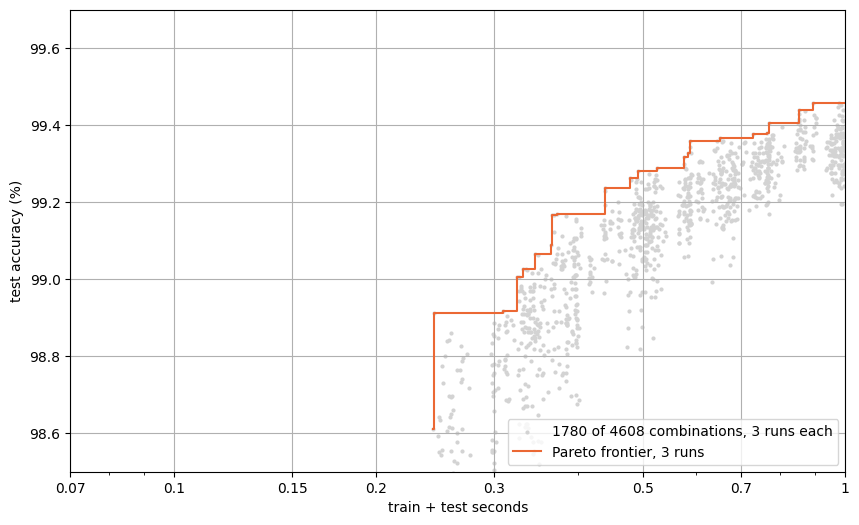

In [ ]:
file_with_3_runs = 'single_model_grid_search_results_with_3_runs.jsonl'
results_with_3_runs = results_saved_in(file_with_3_runs)
for combination in combinations[len(results_with_3_runs):]:
    results_with_3_runs.append(mean_seconds_and_accuracy(combination, runs=3))
    save_result(results_with_3_runs[-1], file_with_3_runs)
    if len(results_with_3_runs) % 20 == 0:
        plot_pareto_frontier(results_with_3_runs)
plot_pareto_frontier(results_with_3_runs)

In [ ]:
def results_close_to_the_pareto_frontier(results, accuracy_margin=0.05, longest_seconds=1):
    frontier = pareto_frontier(results)

    def best_accuracy_within(seconds):
        return max(point['accuracy'] for point in frontier if point['seconds'] <= seconds)

    return [result for result in results if result['seconds'] <= longest_seconds
            and result['accuracy'] > best_accuracy_within(result['seconds']) - accuracy_margin]


file_with_30_runs = 'single_model_grid_search_results_with_30_runs.jsonl'
results_with_30_runs = results_saved_in(file_with_30_runs)
candidates = results_close_to_the_pareto_frontier(results_with_3_runs)
for candidate in candidates[len(results_with_30_runs):]:
    combination = {setting: candidate[setting] for setting in values_of_each_setting}
    results_with_30_runs.append(mean_seconds_and_accuracy(combination, runs=30))
    save_result(results_with_30_runs[-1], file_with_30_runs)
    plot_pareto_frontier(results_with_3_runs, results_with_30_runs)
plot_pareto_frontier(results_with_3_runs, results_with_30_runs)

In [ ]:
for point in pareto_frontier(results_with_30_runs):
    print(f"{point['seconds']:.4f} ± {point['seconds_standard_error']:.4f} s  "
          f"{point['accuracy']:.2f} ± {point['accuracy_standard_error']:.2f} %  ",
          {setting: point[setting] for setting in values_of_each_setting})